# 13 — Representative stock-year daily predictions

This notebook shows unsmoothed daily actual and predicted closing-auction volumes for the six stocks in Notebook 12.

To avoid cherry-picking either an unusually good or unusually bad year, each stock's representative year is selected mechanically: compute annual daily log RMSE for 2016–2025, find the stock's median annual RMSE, and choose the year closest to that median. The five largest absolute log errors in the selected year are marked on each chart.

The logarithmic vertical axis is only an axis transformation; no rolling mean, median, or other smoothing is applied.

In [1]:
from pathlib import Path
import sys
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 130})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")
sys.path.insert(0, str(PROJECT_ROOT))

from notebooks.modeling_utils import forecast_metrics

SOURCE = (
    PROJECT_ROOT / "outputs" / "eda" / "12_selected_stock_predictions"
    / "selected_stock_daily_walk_forward_predictions.parquet"
)
OUT = PROJECT_ROOT / "outputs" / "eda" / "13_representative_stock_year_daily"
OUT.mkdir(parents=True, exist_ok=True)

PROFILES = {
    47896: ("JPM", "large / high liquidity"),
    87267: ("BLK", "large / moderate liquidity"),
    80432: ("AEO", "mid-size / high liquidity"),
    11018: ("FBP", "mid-size / moderate liquidity"),
    76732: ("DIN", "small / moderate liquidity"),
    11267: ("CATO", "small / low liquidity"),
}
PERMNO_ORDER = list(PROFILES)

con = duckdb.connect()
predictions = con.execute(f"SELECT * FROM read_parquet('{SOURCE}') WHERE prediction IS NOT NULL").df()
predictions["date"] = pd.to_datetime(predictions["date"])
predictions["year"] = predictions["date"].dt.year
predictions["absolute_log_error"] = np.abs(
    np.log1p(predictions["prediction"]) - np.log1p(predictions["auction_volume"])
)

## Select a representative year for each stock

In [2]:
annual_rows = []
for (permno, year), frame in predictions.groupby(["permno", "year"]):
    ticker, profile = PROFILES[permno]
    annual_rows.append({
        "permno": permno, "ticker": ticker, "profile": profile, "year": year,
        **forecast_metrics(frame["auction_volume"], frame["prediction"]),
    })

annual_metrics = pd.DataFrame(annual_rows)
annual_metrics["median_stock_rmse"] = annual_metrics.groupby("permno")["rmse_log"].transform("median")
annual_metrics["distance_from_median_rmse"] = np.abs(
    annual_metrics["rmse_log"] - annual_metrics["median_stock_rmse"]
)
selected_years = (
    annual_metrics.sort_values(["permno", "distance_from_median_rmse", "year"])
    .groupby("permno", as_index=False).first()
)
selected_years.to_csv(OUT / "representative_stock_years.csv", index=False)
annual_metrics.to_csv(OUT / "stock_year_daily_metrics.csv", index=False)
display(selected_years[[
    "ticker", "profile", "year", "observations", "rmse_log", "wape",
    "spearman", "aggregate_bias", "median_stock_rmse",
]])

,ticker,profile,year,observations,rmse_log,wape,spearman,aggregate_bias,median_stock_rmse
0,FBP,mid-size / moderate liquidity,2021,252,0.4877,0.4153,0.2272,-0.2057,0.4702
1,CATO,small / low liquidity,2017,251,0.5512,0.4636,0.4178,-0.1960,0.5452
2,JPM,large / high liquidity,2021,252,0.3577,0.3082,0.5399,-0.0751,0.3665
3,DIN,small / moderate liquidity,2019,251,0.4585,0.3712,0.3343,-0.0731,0.4568
4,AEO,mid-size / high liquidity,2019,251,0.4297,0.3499,0.3963,-0.0036,0.4264
5,BLK,large / moderate liquidity,2022,251,0.4099,0.3497,0.4262,-0.1136,0.4089


## Unsmoothed daily actual versus predicted values

Every line segment below is a daily value. Red crosses identify the five dates with the largest absolute error in log volume for that stock-year. Because the model is optimized in log space, these are the largest proportional-scale misses rather than necessarily the largest share-count misses.

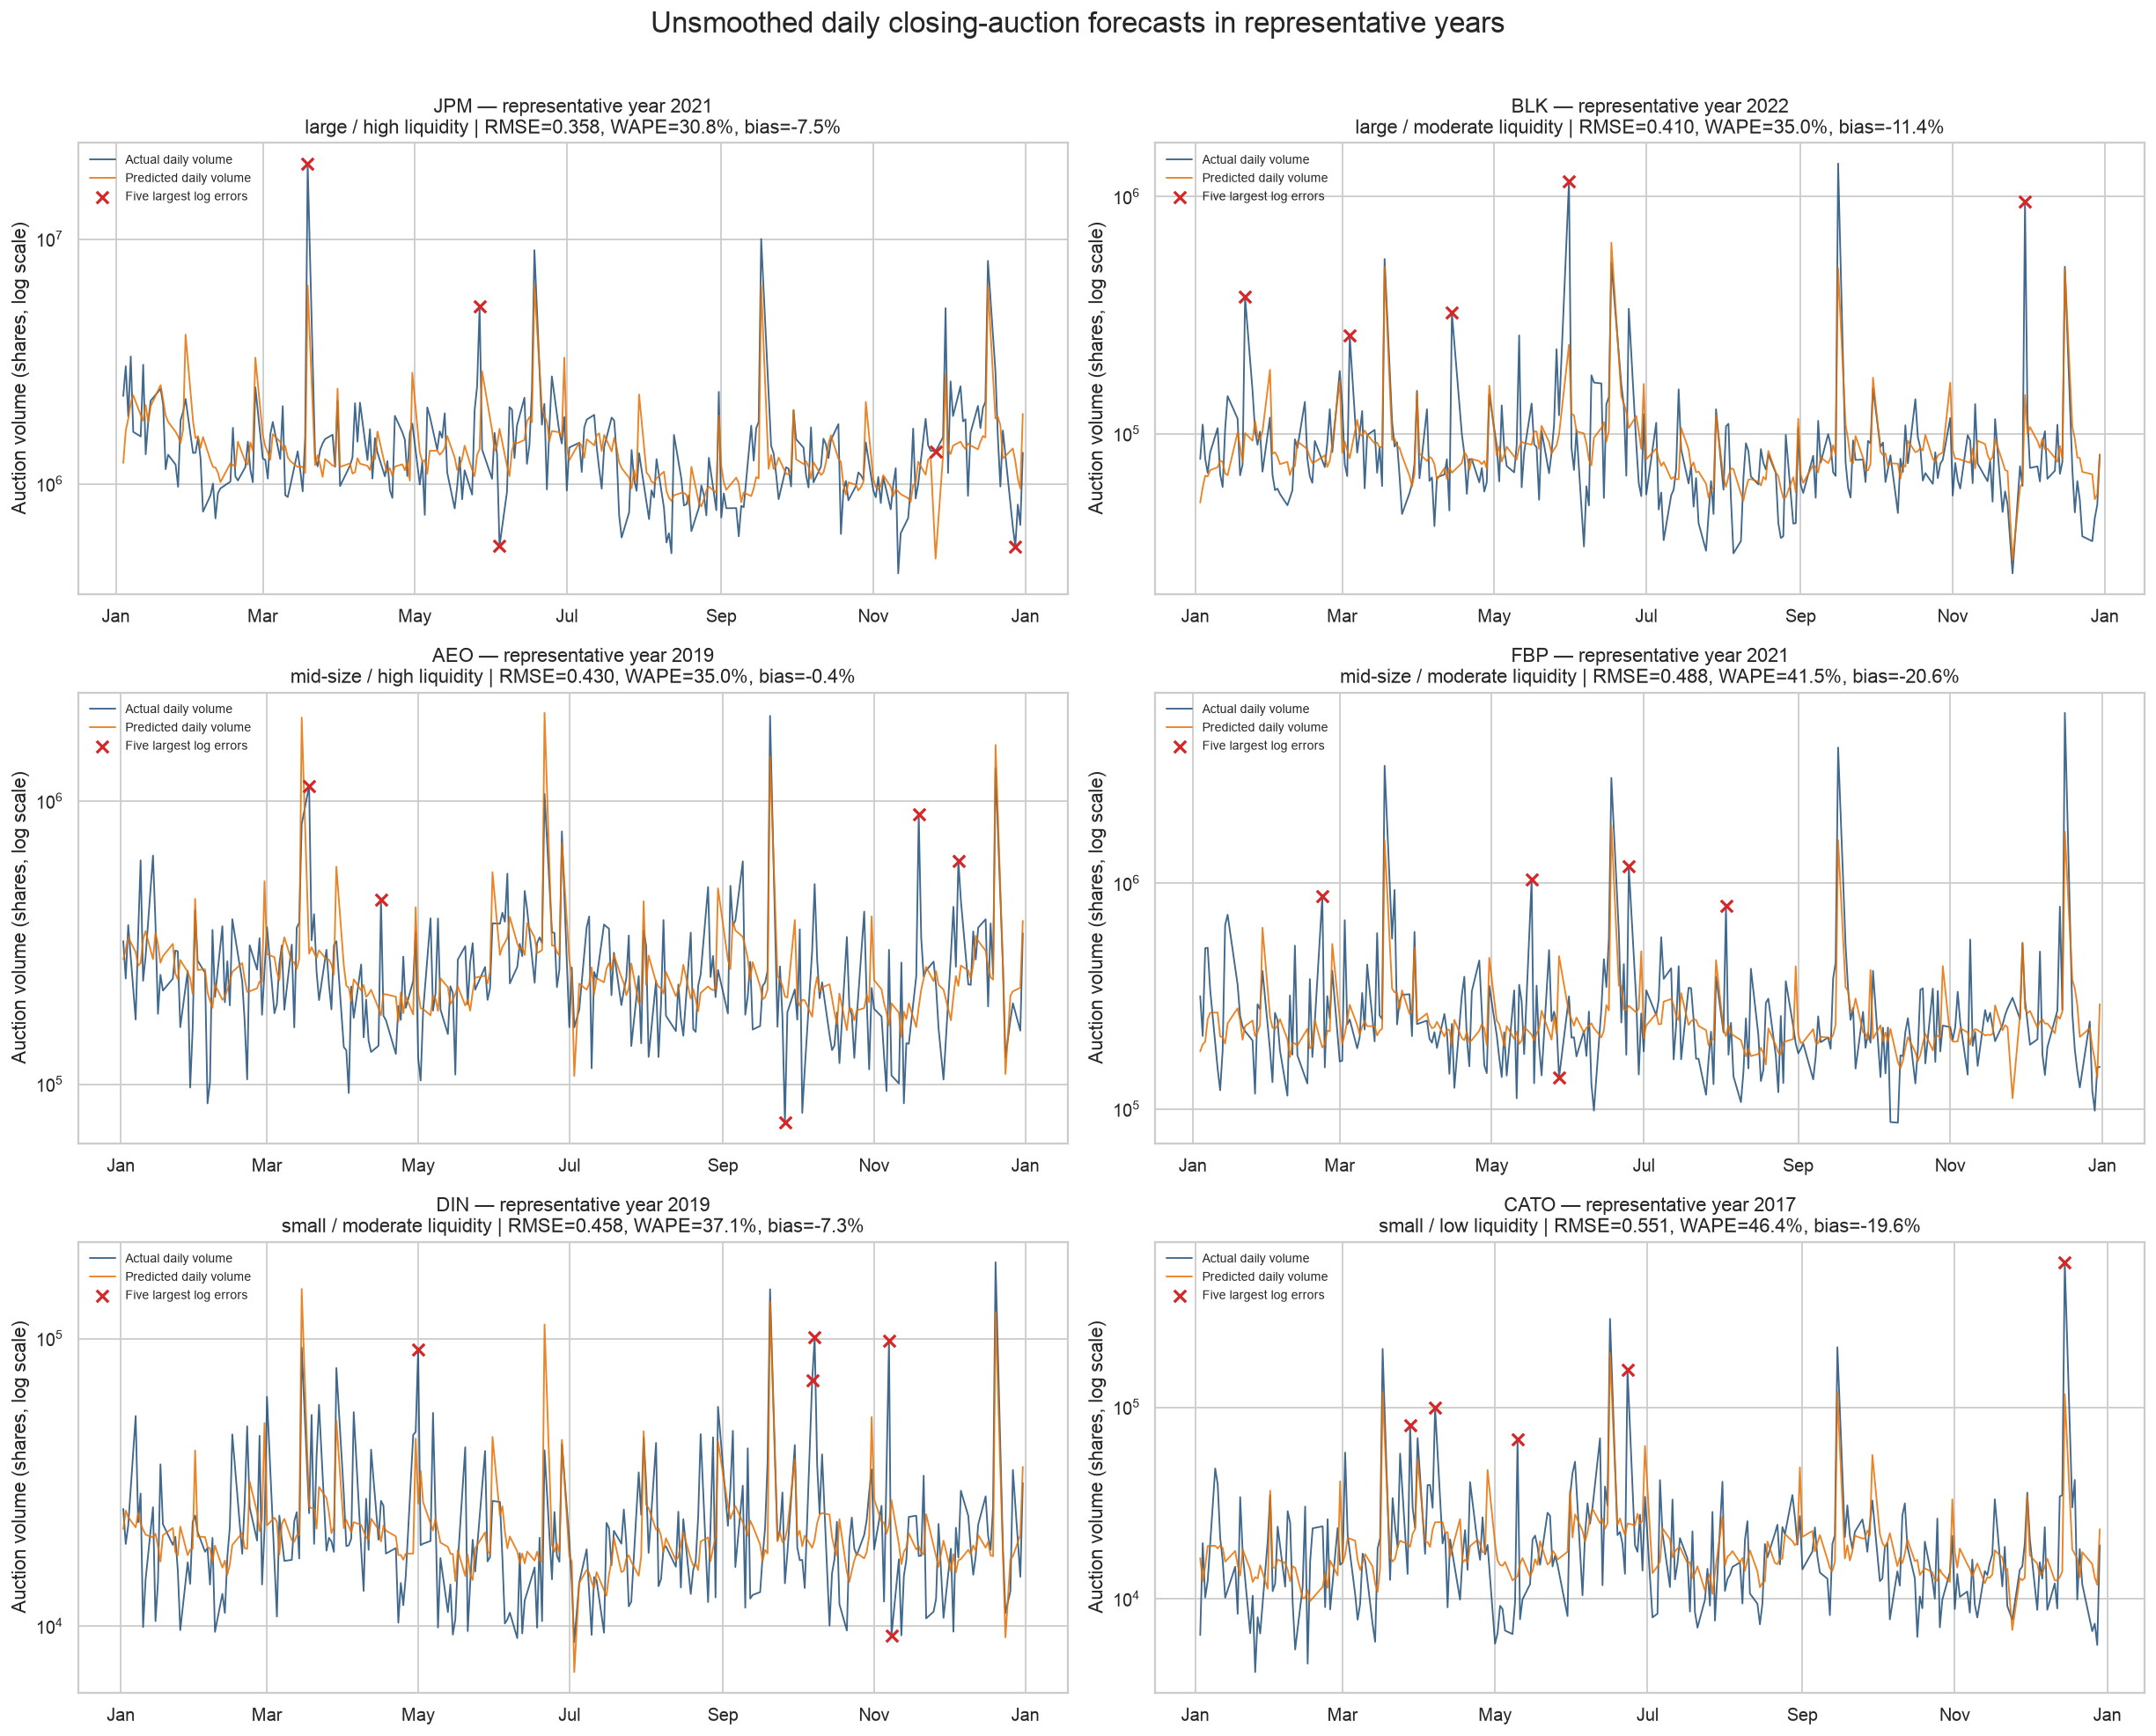

,permno,ticker,year,date,auction_volume,prediction,absolute_log_error,prediction_to_actual_ratio
10,80432,AEO,2019,2019-11-19,900305,"187,216.4240",1.5705,0.2079
11,80432,AEO,2019,2019-03-18,1129408,"289,014.3913",1.3630,0.2559
12,80432,AEO,2019,2019-09-26,73178,"204,280.5244",1.0266,2.7916
13,80432,AEO,2019,2019-12-05,615138,"222,422.3637",1.0173,0.3616
14,80432,AEO,2019,2019-04-16,447466,"175,178.5528",0.9378,0.3915
5,87267,BLK,2022,2022-11-30,954362,"145,858.3100",1.8784,0.1528
6,87267,BLK,2022,2022-05-31,1162959,"237,414.1698",1.5889,0.2041
7,87267,BLK,2022,2022-04-14,323362,"68,580.9044",1.5507,0.2121
8,87267,BLK,2022,2022-01-21,377521,"100,833.0989",1.3202,0.2671
9,87267,BLK,2022,2022-03-04,259510,"79,042.6876",1.1888,0.3046


In [3]:
fig, axes = plt.subplots(3, 2, figsize=(19, 15))
largest_miss_rows = []

for ax, permno in zip(axes.flat, PERMNO_ORDER):
    selected = selected_years[selected_years["permno"] == permno].iloc[0]
    year = int(selected["year"])
    ticker, profile = PROFILES[permno]
    frame = predictions[(predictions["permno"] == permno) & (predictions["year"] == year)].copy()
    largest = frame.nlargest(5, "absolute_log_error")

    ax.plot(frame["date"], frame["auction_volume"], color="#1F4E79", linewidth=1.05,
            alpha=0.85, label="Actual daily volume")
    ax.plot(frame["date"], frame["prediction"], color="#E76F00", linewidth=1.05,
            alpha=0.85, label="Predicted daily volume")
    ax.scatter(largest["date"], largest["auction_volume"], marker="x", s=55,
               linewidths=1.8, color="#D62728", label="Five largest log errors", zorder=5)
    ax.set_yscale("log")
    ax.set_title(
        f"{ticker} — representative year {year}\n{profile} | "
        f"RMSE={selected['rmse_log']:.3f}, WAPE={selected['wape']:.1%}, "
        f"bias={selected['aggregate_bias']:.1%}"
    )
    ax.set_ylabel("Auction volume (shares, log scale)")
    ax.set_xlabel("")
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.legend(frameon=False, fontsize=8, loc="upper left")

    for _, row in largest.iterrows():
        largest_miss_rows.append({
            "permno": permno, "ticker": ticker, "year": year, "date": row["date"],
            "auction_volume": row["auction_volume"], "prediction": row["prediction"],
            "absolute_log_error": row["absolute_log_error"],
            "prediction_to_actual_ratio": row["prediction"] / row["auction_volume"]
                if row["auction_volume"] > 0 else np.nan,
        })

fig.suptitle("Unsmoothed daily closing-auction forecasts in representative years", fontsize=18, y=1.01)
fig.tight_layout()
figure_path = OUT / "representative_stock_year_daily_actual_vs_predicted.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

largest_misses = pd.DataFrame(largest_miss_rows).sort_values(["ticker", "absolute_log_error"], ascending=[True, False])
largest_misses.to_csv(OUT / "representative_year_largest_daily_misses.csv", index=False)
display(largest_misses)

In [4]:
artifacts = pd.DataFrame({
    "artifact": ["Representative years", "All stock-year metrics", "Largest daily misses", "Daily figure"],
    "path": [
        OUT / "representative_stock_years.csv", OUT / "stock_year_daily_metrics.csv",
        OUT / "representative_year_largest_daily_misses.csv", figure_path,
    ],
})
artifacts["path"] = artifacts["path"].astype(str)
artifacts.to_csv(OUT / "artifact_manifest.csv", index=False)
display(artifacts)

,artifact,path
0,Representative years,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
1,All stock-year metrics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
2,Largest daily misses,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
3,Daily figure,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
